# Tuning runs: LR sweeps

Reads only `results/` (committed), so it runs anywhere after `git pull`. Refresh `results/` on the cluster first:
`uv run --frozen python analysis/collect_results.py`, then commit and push.

The optimum per shape is picked by `collect_results.py` (lowest final val loss, CLAUDE.md "Tuning protocol");
this notebook only plots it, to check how sharp each optimum is and whether any run was unstable.

In [7]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS = Path("../results") if Path("../results").exists() else Path("results")  # from analysis/ or the repo root
SHAPES = ["256x64", "384x28", "512x16", "640x10", "1024x4"]  # deep -> wide
PARAMS = {"sp": "SP", "completep": "CompleteP"}
SHAPE_COLORS = dict(zip(SHAPES, plt.cm.viridis(np.linspace(0.0, 0.85, len(SHAPES)))))  # ordinal: deep -> wide

runs = pd.read_csv(RESULTS / "runs.csv")
tune = runs[runs["kind"] == "tune"].copy() if "kind" in runs else runs.iloc[0:0]
best = pd.read_csv(RESULTS / "best_lr.csv")


def load(name, file):
    path = RESULTS / "runs" / name / file
    return pd.read_csv(path) if path.exists() else None


print(f"{len(tune)} tuning runs, {(tune['status'] == 'finished').sum()} finished")

40 tuning runs, 40 finished


## Status
Any run that is not finished (still running, crashed or diverged) is listed here.

In [8]:
tune[tune["status"] != "finished"][["name", "max_iters", "last_eval_iter", "status"]]

,name,max_iters,last_eval_iter,status


In [9]:
best

,parameterization,shape,best_lr,val_loss,lrs_tried,unfinished,on_edge
0,completep,256x64,0.007812,5.561228,0.000976562;0.00195312;0.00390625;0.0078125;0....,0,False
1,completep,512x16,0.007812,5.430040,0.000976562;0.00195312;0.00390625;0.0078125;0....,0,False
2,completep,1024x4,0.001953,5.492287,0.000976562;0.00195312;0.00390625;0.0078125;0....,0,False
3,sp,256x64,0.000600,6.060480,0.00015;0.0003;0.0006;0.0012;0.0024,0,False
4,sp,384x28,0.000600,5.709008,0.00015;0.0003;0.0006;0.0012;0.0024,0,False
5,sp,512x16,0.001200,5.522054,0.00015;0.0003;0.0006;0.0012;0.0024,0,False
6,sp,640x10,0.001200,5.386361,0.00015;0.0003;0.0006;0.0012;0.0024,0,False
7,sp,1024x4,0.001200,5.396256,0.00015;0.0003;0.0006;0.0012;0.0024,0,False


## Final val loss vs LR

One line per shape. The star is the optimum. A flat bottom means the choice of LR matters little there;
an optimum at the end of a line means the edge rule applies (see `results/best_lr.md`).
Under CompleteP the optima should line up across shapes; under SP they are expected to drift.

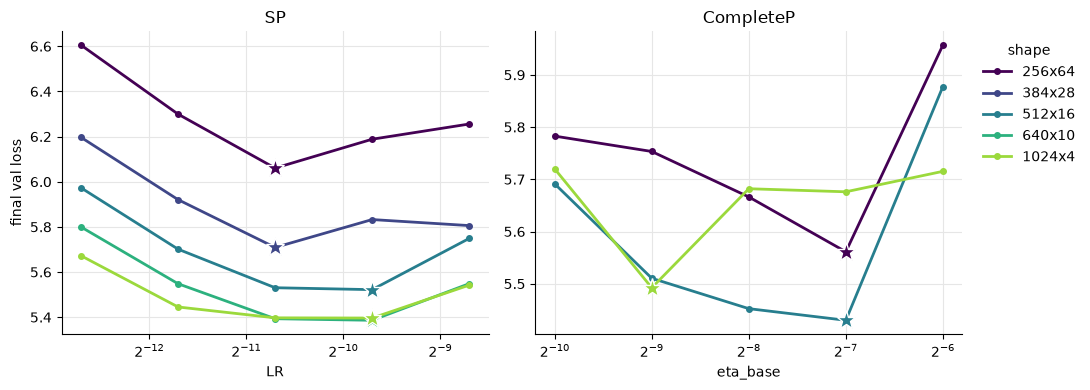

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), squeeze=False)
for ax, (param, title) in zip(axes[0], PARAMS.items()):
    for shape in SHAPES:
        g = tune[(tune["parameterization"] == param) & (tune["shape"] == shape) & (tune["status"] == "finished")]
        if g.empty:
            continue
        g = g.sort_values("lr")
        ax.plot(g["lr"], g["final_val_loss"], marker="o", markersize=4, linewidth=2,
                color=SHAPE_COLORS[shape], label=shape)
        b = g.loc[g["final_val_loss"].idxmin()]
        ax.plot(b["lr"], b["final_val_loss"], marker="*", markersize=14, color=SHAPE_COLORS[shape],
                markeredgecolor="white", linestyle="none")
    ax.set_xscale("log", base=2)
    ax.set_xlabel("LR" if param == "sp" else "eta_base")
    ax.set_title(title)
    ax.grid(True, color="0.9")
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].set_ylabel("final val loss")
handles = {l: h for ax in axes[0] for h, l in zip(*ax.get_legend_handles_labels())}  # all shapes, from both panels
order = [s for s in SHAPES if s in handles]
axes[0, -1].legend([handles[s] for s in order], order, title="shape", frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1.0))
fig.tight_layout()

## Optimal LR vs shape

Same optima as above, against depth. Each grid step is x2, so a flat line = LR transfers across shapes.

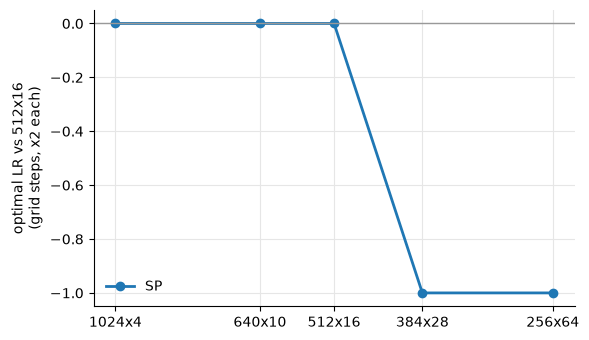

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for param, title in PARAMS.items():
    b = best[best["parameterization"] == param].copy()
    if b.empty:
        continue
    b["L"] = b["shape"].str.split("x").str[1].astype(int)
    b = b.sort_values("L")
    ref = b.loc[b["shape"] == "512x16", "best_lr"]
    rel = np.log2(b["best_lr"] / ref.iloc[0]) if len(ref) else np.full(len(b), np.nan)
    ax.plot(b["L"], rel, marker="o", linewidth=2, label=title)
ax.axhline(0, color="0.6", linewidth=1)
ax.set_xscale("log", base=2)
ax.set_xticks([4, 10, 16, 28, 64], ["1024x4", "640x10", "512x16", "384x28", "256x64"])
ax.set_ylabel("optimal LR vs 512x16\n(grid steps, x2 each)")
ax.grid(True, color="0.9")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()

## Loss curves

One panel per (parameterization, shape), one line per LR (light = small, dark = large).
Lines: training loss (`train.csv`, every 10 steps, smoothed). Dots: val loss at each eval (`eval.csv`).
Look for spikes or a loss that stops falling at the large LRs: that run's final loss is instability, not a clean LR effect.

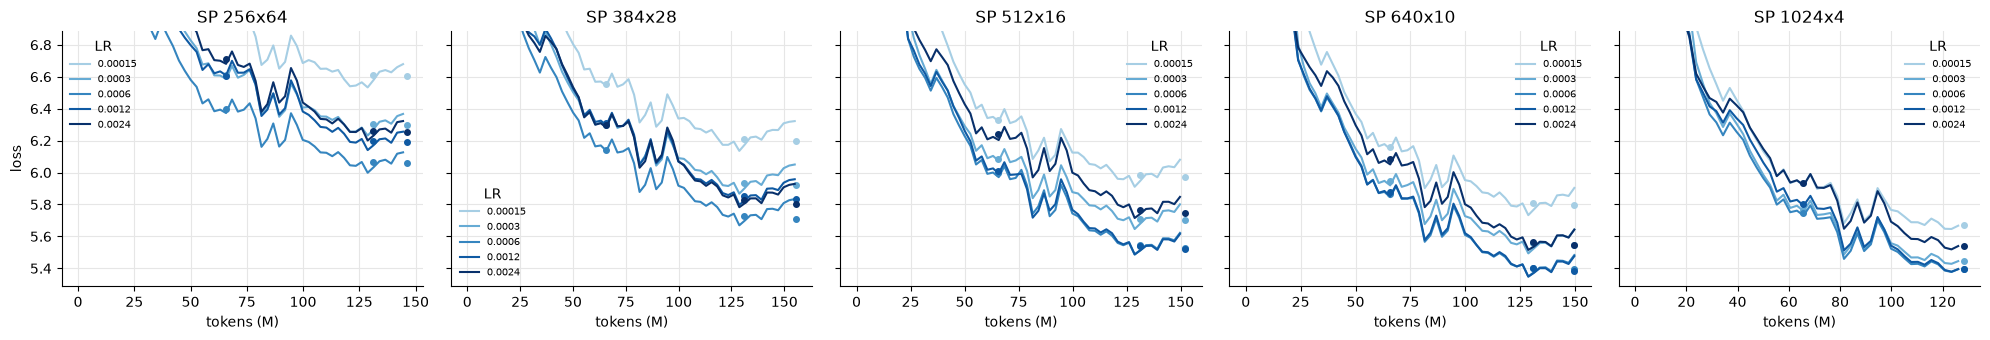

In [5]:
SMOOTH = 5  # rolling mean over 5 logged points = 50 steps

for param, title in PARAMS.items():
    shapes = [s for s in SHAPES if ((tune["parameterization"] == param) & (tune["shape"] == s)).any()]
    if not shapes:
        continue
    fig, axes = plt.subplots(1, len(shapes), figsize=(4 * len(shapes), 3.5), squeeze=False, sharey=True)
    for ax, shape in zip(axes[0], shapes):
        g = tune[(tune["parameterization"] == param) & (tune["shape"] == shape)].sort_values("lr")
        colors = plt.cm.Blues(np.linspace(0.35, 1.0, len(g)))
        for (_, run), color in zip(g.iterrows(), colors):
            tr, ev = load(run["name"], "train.csv"), load(run["name"], "eval.csv")
            label = f"{run['lr']:.3g}" + ("" if run["status"] == "finished" else " (not finished)")
            if tr is not None and len(tr):
                ax.plot(tr["tokens"] / 1e6, tr["loss"].rolling(SMOOTH, min_periods=1).mean(),
                        color=color, linewidth=1.5, label=label)
            if ev is not None and len(ev):
                ax.plot(ev["tokens"] / 1e6, ev["val_loss"], color=color, marker="o", markersize=4, linestyle="none")
        ax.set_title(f"{title} {shape}")
        ax.set_xlabel("tokens (M)")
        ax.grid(True, color="0.9")
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(title="LR", fontsize=7, frameon=False)
    axes[0, 0].set_ylabel("loss")
    lo = tune.loc[tune["parameterization"] == param, "final_val_loss"].min()
    if pd.notna(lo):
        axes[0, 0].set_ylim(lo - 0.1, lo + 1.5)  # zoom on the end of training; the early drop is not informative
    fig.tight_layout()

## Learning-rate schedule check

The LR each run actually used (`train.csv`), for the 512x16 runs: 10% linear warmup, then cosine to 0.

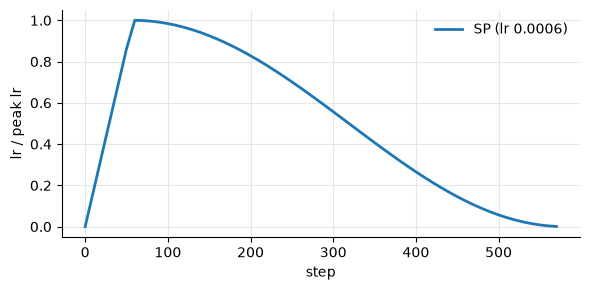

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
for param, title in PARAMS.items():
    g = tune[(tune["parameterization"] == param) & (tune["shape"] == "512x16")]
    if g.empty:
        continue
    run = g.sort_values("lr").iloc[len(g) // 2]  # the middle LR of the grid
    tr = load(run["name"], "train.csv")
    if tr is not None:
        ax.plot(tr["iter"], tr["lr"] / tr["lr"].max(), linewidth=2, label=f"{title} (lr {run['lr']:.3g})")
ax.set_xlabel("step")
ax.set_ylabel("lr / peak lr")
ax.grid(True, color="0.9")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()